# 04 — Modeling

Notebook ini menjalankan tahap **Modeling** CRISP-DM untuk klasifikasi biner audio:

- `1 = berisik`
- `0 = non-berisik`

Tujuan tahap ini adalah membandingkan empat model (Logistic Regression, SVM-RBF, Random Forest, Gradient Boosting) dengan validasi silang berbasis NIM, mengunci hold-out NIM sebelum pemilihan model, memilih dan menala hyperparameter lewat `GridSearchCV` berbasis `GroupKFold`, lalu menyimpan pipeline terpilih beserta konfigurasi dan daftar fiturnya.

## Masukan

- `artifacts/features.csv`: 176 baris file final dan 12 fitur dari Tahap 03.
- `artifacts/selected_features.txt`: kandidat fitur eksploratif (hanya referensi; seleksi final dipelajari di dalam `Pipeline`).
- `artifacts/03_data_preparation/validation_summary.json`: gerbang validasi Tahap 03.

## Keluaran utama

- `artifacts/best_model.joblib`: pipeline terpilih (scaler + seleksi fitur + klasifier).
- `artifacts/04_modeling/model_config.json`: konfigurasi, parameter terbaik, dan daftar NIM train/test.
- `artifacts/04_modeling/holdout_split.csv` dan `holdout_file_split.csv`: pembagian hold-out terkunci per NIM dan per file.
- `artifacts/04_modeling/model_comparison.csv`, `cv_fold_scores.csv`, `grid_search_results.csv`.
- `artifacts/04_modeling/`: laporan, validasi, ringkasan, dan gambar.

## Batasan yang dipegang

1. Hold-out 20% NIM dikunci sebelum pemilihan model dan **tidak pernah** dipakai oleh `GridSearchCV` atau perbandingan model; uji hold-out dilakukan di Tahap 05.
2. Split selalu berbasis NIM: satu NIM tidak boleh muncul di dua sisi split maupun antar fold.
3. Scaler, seleksi fitur, dan klasifier berada di dalam satu `Pipeline` sehingga hanya di-fit pada training fold.
4. Tidak ada PCA dan tidak ada training pada file karantina.
5. Semua angka dan grafik berasal dari eksekusi data nyata; klaim ROC-AUC hold-out ≥ 0,85 baru dinilai pada Tahap 05.
6. `raw_audio/` tidak diubah.


In [1]:
import json
import platform
import warnings
from datetime import datetime, timezone
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found.*")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, make_scorer, precision_score, recall_score
from sklearn.model_selection import (
    GridSearchCV,
    GroupKFold,
    GroupShuffleSplit,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 120)

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.titleweight"] = "bold"

RANDOM_STATE = 42

library_versions = pd.DataFrame(
    {
        "komponen": [
            "Python",
            "numpy",
            "pandas",
            "scikit-learn",
            "joblib",
            "matplotlib",
            "seaborn",
        ],
        "versi": [
            platform.python_version(),
            np.__version__,
            pd.__version__,
            __import__("sklearn").__version__,
            joblib.__version__,
            plt.matplotlib.__version__,
            sns.__version__,
        ],
    }
)

display(library_versions)


,komponen,versi
0,Python,3.11.9
1,numpy,2.4.6
2,pandas,2.3.3
3,scikit-learn,1.8.0
4,joblib,1.5.3
5,matplotlib,3.11.0
6,seaborn,0.13.2


In [2]:
PROJECT_ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "raw_audio").is_dir() and (candidate / "artifacts").is_dir():
        PROJECT_ROOT = candidate.resolve()
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError("Folder proyek dengan raw_audio/ dan artifacts/ tidak ditemukan.")

ARTIFACT_ROOT = PROJECT_ROOT / "artifacts"
ARTIFACT_DIR = ARTIFACT_ROOT / "04_modeling"
FIGURE_DIR = ARTIFACT_DIR / "figures"

FEATURES_PATH = ARTIFACT_ROOT / "features.csv"
SELECTED_FEATURES_PATH = ARTIFACT_ROOT / "selected_features.txt"
STAGE3_VALIDATION_PATH = ARTIFACT_ROOT / "03_data_preparation" / "validation_summary.json"

MODEL_PATH = ARTIFACT_ROOT / "best_model.joblib"
HOLDOUT_SPLIT_PATH = ARTIFACT_DIR / "holdout_split.csv"
HOLDOUT_FILE_PATH = ARTIFACT_DIR / "holdout_file_split.csv"
MODEL_CONFIG_PATH = ARTIFACT_DIR / "model_config.json"
FEATURE_LIST_PATH = ARTIFACT_DIR / "feature_list.txt"

for directory in [ARTIFACT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

IDENTITY_COLUMNS = ["file", "nim", "take", "label"]

FEATURE_COLUMNS = [
    "mse_energy",
    "rms_mean",
    "rms_std",
    "rms_max",
    "rms_min",
    "zcr_mean",
    "zcr_std",
    "spectral_centroid_mean",
    "spectral_centroid_std",
    "spectral_flatness_mean",
    "spectral_rolloff_mean",
    "spectral_bandwidth_mean",
]

LABEL_NAME_MAP = {0: "non-berisik", 1: "berisik"}

N_SPLITS = 5
TEST_SIZE = 0.2
SCORING = "roc_auc"
RANDOM_STATE = 42

MODEL_CANDIDATES = [
    "Logistic Regression",
    "SVM-RBF",
    "Random Forest",
    "Gradient Boosting",
]

CONFIG = pd.DataFrame(
    {
        "parameter": [
            "project_root",
            "artifact_dir",
            "n_splits (GroupKFold)",
            "test_size NIM (GroupShuffleSplit)",
            "scoring",
            "random_state",
            "jumlah fitur",
            "kandidat model",
        ],
        "nilai": [
            str(PROJECT_ROOT),
            str(ARTIFACT_DIR),
            N_SPLITS,
            TEST_SIZE,
            SCORING,
            RANDOM_STATE,
            len(FEATURE_COLUMNS),
            ", ".join(MODEL_CANDIDATES),
        ],
    }
)

display(CONFIG)
print(f"Model akan disimpan di: {MODEL_PATH}")


,parameter,nilai
0,project_root,C:\Users\ASUS\Downloads\dataset_30_detik
1,artifact_dir,C:\Users\ASUS\Downloads\dataset_30_detik\artif...
2,n_splits (GroupKFold),5
3,test_size NIM (GroupShuffleSplit),0.2
4,scoring,roc_auc
5,random_state,42
6,jumlah fitur,12
7,kandidat model,"Logistic Regression, SVM-RBF, Random Forest, G..."


Model akan disimpan di: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\best_model.joblib


## 1. Pintu masuk: hasil Tahap 03

Section ini memastikan data fitur dari Tahap 03 layak dipakai sebelum ada satu pun pelatihan model.

Syarat yang diverifikasi:

1. `validation_summary.json` Tahap 03 berstatus **PASS** dengan seluruh pemeriksaan lulus.
2. `features.csv` berisi tepat 176 baris, kolom identitas + 12 fitur, tanpa NaN/Inf, dan seluruh identitas unik.
3. Distribusi kelas 88 non-berisik : 88 berisik dan 34 NIM, semua NIM memiliki kedua kelas.
4. `selected_features.txt` berisi 8 kandidat eksploratif; daftar itu **hanya referensi** karena seleksi final wajib dipelajari di dalam `Pipeline` pada training fold.

Bila satu saja syarat gagal, notebook berhenti dan Tahap 04 tidak dianggap dimulai.


In [3]:
stage3_validation = json.loads(STAGE3_VALIDATION_PATH.read_text(encoding="utf-8"))
assert stage3_validation["status"] == "PASS", "Validasi Tahap 03 berstatus bukan PASS."
assert (
    stage3_validation["checks_passed"] == stage3_validation["checks_total"]
), "Terdapat pemeriksaan Tahap 03 yang gagal."
assert stage3_validation["n_final"] == 176, "Jumlah file final berubah dari 176."

features = pd.read_csv(FEATURES_PATH)
features["label"] = features["label"].astype(int)
features["take"] = features["take"].astype(int)
features["label_name"] = features["label"].map(LABEL_NAME_MAP)

assert len(features) == 176, f"features.csv berisi {len(features)} baris, bukan 176."
assert list(features.columns[:4]) == IDENTITY_COLUMNS, "Kolom identitas tidak sesuai."
assert set(FEATURE_COLUMNS).issubset(features.columns), "Kolom fitur hilang."
extra_columns = set(features.columns) - set(IDENTITY_COLUMNS + FEATURE_COLUMNS)
assert extra_columns <= {"label_name"}, f"Kolom tak dikenal: {extra_columns}."

feature_values = features[FEATURE_COLUMNS].to_numpy(dtype=float)
assert not features[FEATURE_COLUMNS].isna().any().any(), "features.csv mengandung NaN."
assert np.isfinite(feature_values).all(), "features.csv mengandung Inf."
assert features["file"].is_unique, "Kolom file tidak unik."
assert not features.duplicated(IDENTITY_COLUMNS).any(), "Identitas file/nim/take/label ganda."

class_counts = features["label"].value_counts().to_dict()
assert int(class_counts.get(0, 0)) == 88 and int(class_counts.get(1, 0)) == 88, (
    f"Distribusi kelas berubah: {class_counts}"
)

nims_all = sorted(features["nim"].unique())
assert len(nims_all) == 34, f"Jumlah NIM berubah: {len(nims_all)}"
per_nim_classes = features.groupby("nim")["label"].nunique()
assert (per_nim_classes == 2).all(), "Ada NIM yang tidak memiliki kedua kelas."

selected_features = [
    line.split("|")[-1].strip()
    for line in SELECTED_FEATURES_PATH.read_text(encoding="utf-8").splitlines()
    if line.strip() and not line.startswith("#")
]
assert len(selected_features) == 8, f"Kandidat fitur berjumlah {len(selected_features)}, bukan 8."
assert set(selected_features).issubset(
    set(FEATURE_COLUMNS)
), "Kandidat fitur tidak ada di FEATURE_COLUMNS."

input_summary = pd.DataFrame(
    {
        "pemeriksaan": [
            "status validasi Tahap 03",
            "jumlah pemeriksaan Tahap 03 lulus",
            "baris features.csv",
            "fitur numerik tanpa NaN/Inf",
            "distribusi kelas (0 : 1)",
            "jumlah NIM (semua berdua kelas)",
            "kandidat fitur eksploratif",
        ],
        "nilai": [
            stage3_validation["status"],
            f"{stage3_validation['checks_passed']}/{stage3_validation['checks_total']}",
            len(features),
            f"{len(FEATURE_COLUMNS)} fitur",
            f"{int(class_counts[0])} : {int(class_counts[1])}",
            len(nims_all),
            len(selected_features),
        ],
    }
)
display(input_summary)
print("Pintu masuk Tahap 04: LULUS")


,pemeriksaan,nilai
0,status validasi Tahap 03,PASS
1,jumlah pemeriksaan Tahap 03 lulus,28/28
2,baris features.csv,176
3,fitur numerik tanpa NaN/Inf,12 fitur
4,distribusi kelas (0 : 1),88 : 88
5,jumlah NIM (semua berdua kelas),34
6,kandidat fitur eksploratif,8


Pintu masuk Tahap 04: LULUS


## 2. Penguncian hold-out berbasis NIM

Hold-out dibentuk dari **NIM unik**, bukan dari file, menggunakan `GroupShuffleSplit(test_size=0.2, random_state=42)`.

Aturan yang dipegang:

1. Pembagian dibentuk **sebelum** pemilihan model dan disimpan ke `holdout_split.csv` (per NIM) serta `holdout_file_split.csv` (per file).
2. NIM pada sisi test **tidak boleh** muncul di data yang dipakai perbandingan model maupun `GridSearchCV`.
3. Uji terhadap NIM test dilakukan hanya di Tahap 05, sehingga hasil Tahap 04 tidak pernah menyentuh data evaluasi akhir.
4. Seluruh NIM, file, dan kelas yang masuk masing-masing sisi dilaporkan apa adanya, termasuk ketidakseimbangan kelas yang muncul secara alami.


,n_files,n_nim,n_class_0,n_class_1
split,,,,
train,136,27,67,69
test,40,7,21,19


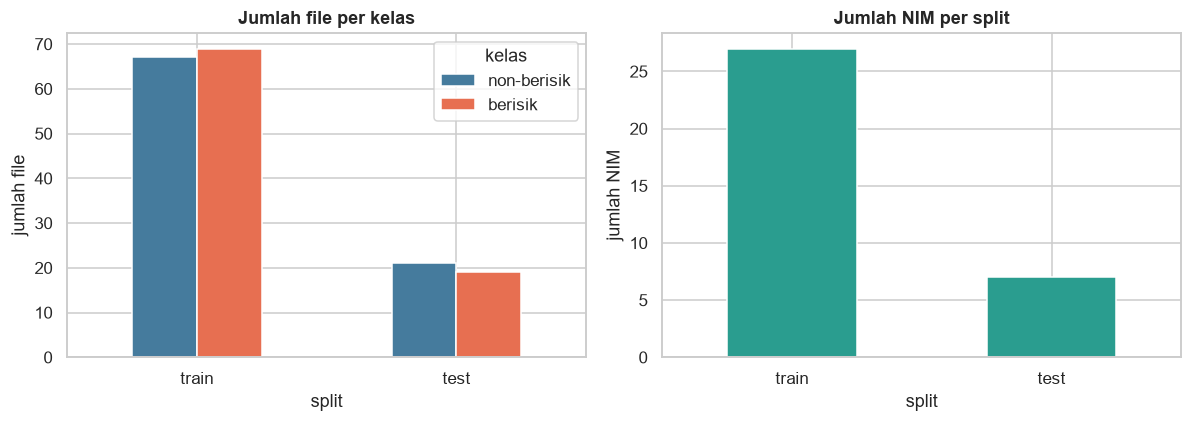

NIM train (27): 24-003, 24-006, 24-007, 24-026, 24-027, 24-031, 24-034, 24-053, 24-071, 24-078, 24-079, 24-081, 24-087, 24-098, 24-101, 24-115, 24-118, 24-125, 24-137, 24-141, 24-157, 24-179, 24-190, 24-196, 24-201, 24-202, 24-228
NIM test  (7): 24-068, 24-100, 24-119, 24-131, 24-145, 24-168, 24-169


In [4]:
nims_all_array = np.array(nims_all)

holdout_splitter = GroupShuffleSplit(
    n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
train_nim_idx, test_nim_idx = next(
    holdout_splitter.split(np.zeros(len(nims_all_array)), groups=nims_all_array)
)
nims_train = sorted(nims_all_array[train_nim_idx].tolist())
nims_test = sorted(nims_all_array[test_nim_idx].tolist())

expected_n_test = int(np.ceil(TEST_SIZE * len(nims_all_array)))
assert len(nims_test) == expected_n_test, (
    f"NIM test {len(nims_test)} tidak sama dengan pembulatan {expected_n_test}."
)
assert set(nims_train).isdisjoint(set(nims_test)), "NIM train dan test beririsan."
assert set(nims_train) | set(nims_test) == set(nims_all), "NIM train + test tidak menutup semua NIM."

features["split"] = np.where(features["nim"].isin(nims_test), "test", "train")
assert set(features.loc[features["split"] == "train", "nim"]) == set(nims_train)
assert set(features.loc[features["split"] == "test", "nim"]) == set(nims_test)

holdout_split = (
    features.groupby(["nim", "split"])
    .agg(
        n_files=("file", "size"),
        n_class_0=("label", lambda values: int((values == 0).sum())),
        n_class_1=("label", lambda values: int((values == 1).sum())),
    )
    .reset_index()
    .sort_values(["split", "nim"])
    .reset_index(drop=True)
)
holdout_split.to_csv(HOLDOUT_SPLIT_PATH, index=False)

holdout_file_split = features[IDENTITY_COLUMNS + ["split"]].copy()
holdout_file_split.to_csv(HOLDOUT_FILE_PATH, index=False)

split_summary = (
    features.groupby("split")
    .agg(
        n_files=("file", "size"),
        n_nim=("nim", "nunique"),
        n_class_0=("label", lambda values: int((values == 0).sum())),
        n_class_1=("label", lambda values: int((values == 1).sum())),
    )
    .reindex(["train", "test"])
)
display(split_summary)

classes_per_nim = features.groupby(["nim", "split"])["label"].nunique()
assert (classes_per_nim == 2).all(), "Ada NIM yang kehilangan satu kelas pada salah satu sisi split."

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
class_by_split = split_summary[["n_class_0", "n_class_1"]].rename(
    columns={"n_class_0": "non-berisik", "n_class_1": "berisik"}
)
class_by_split.plot(kind="bar", ax=axes[0], color=["#457b9d", "#e76f51"])
axes[0].set_title("Jumlah file per kelas")
axes[0].set_xlabel("split")
axes[0].set_ylabel("jumlah file")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)
axes[0].legend(title="kelas")

split_summary["n_nim"].plot(kind="bar", ax=axes[1], color="#2a9d8f")
axes[1].set_title("Jumlah NIM per split")
axes[1].set_xlabel("split")
axes[1].set_ylabel("jumlah NIM")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "holdout_composition.png")
plt.show()

print(f"NIM train ({len(nims_train)}): {', '.join(nims_train)}")
print(f"NIM test  ({len(nims_test)}): {', '.join(nims_test)}")


## 3. Baseline jujur dan pipeline anti-bocor

Sebelum membandingkan model, dua hal ditetapkan:

**Baseline jujur.** `DummyClassifier(strategy="prior")` hanya mengeluarkan probabilitas prior kelas. Dua kelas hampir seimbang, jadi ROC-AUC baseline adalah **0,50**. Semua model di bawah harus dibandingkan dengan angka ini; accuracy saja tidak cukup.

**Pipeline.** Setiap kandidat dibungkus satu `Pipeline`:

1. `StandardScaler` — menyeragamkan skala fitur (logika tetap untuk model berbasis jarak dan koefisien).
2. `SelectKBest(score_func=f_classif, k=...)` — seleksi fitur dipelajari dari data fold latih saja, bukan ditentukan dari seluruh data.
3. klasifier — Logistic Regression, SVM-RBF, Random Forest, atau Gradient Boosting.

Konsekuensinya scaler dan seleksi fitur **tidak pernah** melihat fold uji, tidak ada PCA, dan model akhir yang disimpan adalah pipeline utuh sehingga Tahap 05/06 cukup memuat `best_model.joblib` tanpa langkah tambahan.


In [5]:
SCORING_SET = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
}


def make_pipeline(estimator, k=len(FEATURE_COLUMNS)):
    return Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            ("select", SelectKBest(score_func=f_classif, k=k)),
            ("clf", estimator),
        ]
    )


model_train = features.loc[features["split"] == "train"].reset_index(drop=True)
model_test = features.loc[features["split"] == "test"].reset_index(drop=True)

X_train = model_train[FEATURE_COLUMNS].to_numpy(dtype=float)
y_train = model_train["label"].to_numpy(dtype=int)
groups_train = model_train["nim"].to_numpy()

assert set(model_train["nim"]).isdisjoint(set(model_test["nim"])), "NIM train dan test beririsan."
assert not set(model_train["nim"]) & set(nims_test), "Data latih mengandung NIM hold-out."

cv_splitter = GroupKFold(n_splits=N_SPLITS)

baseline_estimator = DummyClassifier(strategy="prior")
baseline_pipe = make_pipeline(baseline_estimator, k=len(FEATURE_COLUMNS))
baseline_cv = cross_validate(
    baseline_pipe,
    X_train,
    y_train,
    groups=groups_train,
    cv=cv_splitter,
    scoring=SCORING_SET,
    n_jobs=1,
    return_train_score=True,
)
baseline_roc_auc = float(np.mean(baseline_cv["test_roc_auc"]))
assert abs(baseline_roc_auc - 0.5) < 1e-9, f"Baseline ROC-AUC = {baseline_roc_auc}, bukan 0.50."

pipeline_frame = pd.DataFrame(
    {
        "langkah": [name for name, _ in baseline_pipe.steps],
        "estimator": [type(estimator).__name__ for _, estimator in baseline_pipe.steps],
        "fit_pada": ["training fold", "training fold", "training fold"],
    }
)
display(pipeline_frame)
print(f"Baseline ROC-AUC (GroupKFold, {N_SPLITS} fold): {baseline_roc_auc:.4f}")
print(
    f"Data latih: {len(model_train)} file, {model_train['nim'].nunique()} NIM, "
    f"kelas {model_train['label'].value_counts().sort_index().to_dict()}"
)


,langkah,estimator,fit_pada
0,scaler,StandardScaler,training fold
1,select,SelectKBest,training fold
2,clf,DummyClassifier,training fold


Baseline ROC-AUC (GroupKFold, 5 fold): 0.5000
Data latih: 136 file, 27 NIM, kelas {0: 67, 1: 69}


## 4. Perbandingan empat model dengan GroupKFold

Empat kandidat dibandingkan pada **data latih saja** (NIM hold-out tidak disentuh) memakai `GroupKFold(n_splits=5)` dengan `groups = NIM`, sehingga satu NIM selalu berada di satu sisi fold.

Kondisi perbandingan:

1. Semua model memakai pipeline yang sama dan **seluruh 12 fitur** (`k=12`) dengan parameter bawaan yang dirujuk secara eksplisit; penyesuaian hyperparameter dilakukan pada Section 5 untuk kandidat terbaik.
2. Metrik utama `roc_auc`; accuracy, precision, recall, dan F1 dilaporkan pendamping.
3. Skor per fold disimpan (`cv_fold_scores.csv`) agar selisih antar fold terlihat, bukan hanya rata-rata.
4. Baseline ditampilkan pada tabel dan grafik yang sama sebagai garis pembanding 0,50.
5. Perbandingan ini **bukan** klaim kelayakan; kelayakan (ROC-AUC ≥ 0,85) diukur pada hold-out di Tahap 05.


,model,cv_roc_auc_mean,cv_roc_auc_std,train_roc_auc_mean,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean
0,Logistic Regression,0.8349,0.0795,0.8875,0.7204,0.7633,0.7026,0.7096
1,Random Forest,0.7811,0.0712,1.0000,0.6989,0.6995,0.7641,0.7167
2,SVM-RBF,0.7738,0.0842,0.9110,0.7127,0.7667,0.6892,0.6978
3,Gradient Boosting,0.7569,0.0899,1.0000,0.6859,0.6931,0.7508,0.7084
4,Baseline (prior),0.5000,0.0000,0.5000,0.4777,0.3931,0.8000,0.5268


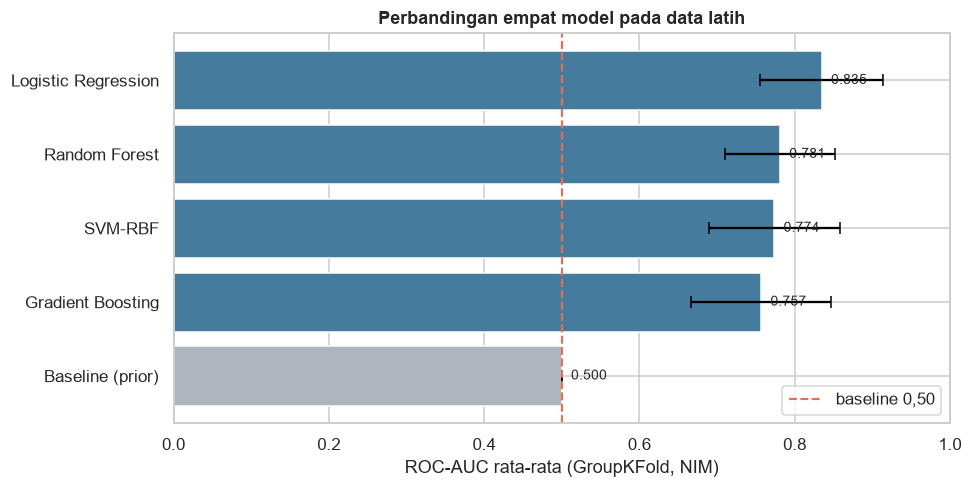

Kandidat terbaik dari perbandingan: Logistic Regression
Posisi baseline pada peringkat: 5 dari 5


In [6]:
reference_models = {
    "Logistic Regression": LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=5000,
        random_state=RANDOM_STATE,
    ),
    "SVM-RBF": SVC(
        C=1.0,
        kernel="rbf",
        gamma="scale",
        probability=True,
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE,
    ),
}

assert sorted(reference_models) == sorted(MODEL_CANDIDATES), "Daftar model tidak sesuai config."

comparison_rows = []
fold_rows = []

for model_name, estimator in reference_models.items():
    pipe = make_pipeline(estimator, k=len(FEATURE_COLUMNS))
    cv_scores = cross_validate(
        pipe,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv_splitter,
        scoring=SCORING_SET,
        n_jobs=1,
        return_train_score=True,
    )
    comparison_rows.append(
        {
            "model": model_name,
            "cv_roc_auc_mean": float(np.mean(cv_scores["test_roc_auc"])),
            "cv_roc_auc_std": float(np.std(cv_scores["test_roc_auc"])),
            "train_roc_auc_mean": float(np.mean(cv_scores["train_roc_auc"])),
            "cv_accuracy_mean": float(np.mean(cv_scores["test_accuracy"])),
            "cv_precision_mean": float(np.mean(cv_scores["test_precision"])),
            "cv_recall_mean": float(np.mean(cv_scores["test_recall"])),
            "cv_f1_mean": float(np.mean(cv_scores["test_f1"])),
        }
    )
    for fold_index, score in enumerate(cv_scores["test_roc_auc"]):
        fold_rows.append(
            {"model": model_name, "fold": fold_index, "roc_auc": float(score)}
        )

comparison_rows.append(
    {
        "model": "Baseline (prior)",
        "cv_roc_auc_mean": baseline_roc_auc,
        "cv_roc_auc_std": float(np.std(baseline_cv["test_roc_auc"])),
        "train_roc_auc_mean": float(np.mean(baseline_cv["train_roc_auc"])),
        "cv_accuracy_mean": float(np.mean(baseline_cv["test_accuracy"])),
        "cv_precision_mean": float(np.mean(baseline_cv["test_precision"])),
        "cv_recall_mean": float(np.mean(baseline_cv["test_recall"])),
        "cv_f1_mean": float(np.mean(baseline_cv["test_f1"])),
    }
)
for fold_index, score in enumerate(baseline_cv["test_roc_auc"]):
    fold_rows.append({"model": "Baseline (prior)", "fold": fold_index, "roc_auc": float(score)})

comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("cv_roc_auc_mean", ascending=False)
    .reset_index(drop=True)
)
cv_fold_scores = pd.DataFrame(fold_rows)

comparison.to_csv(ARTIFACT_DIR / "model_comparison.csv", index=False)
cv_fold_scores.to_csv(ARTIFACT_DIR / "cv_fold_scores.csv", index=False)

reference_comparison = comparison.loc[comparison["model"] != "Baseline (prior)"]
best_reference_name = reference_comparison.iloc[0]["model"]
baseline_rank = int(
    comparison.reset_index().loc[comparison["model"] == "Baseline (prior)", "index"].iloc[0]
) + 1

display(comparison.round(4))

fig, ax = plt.subplots(figsize=(9, 4.6))
plot_frame = comparison.sort_values("cv_roc_auc_mean")
colors = ["#adb5bd" if name == "Baseline (prior)" else "#457b9d" for name in plot_frame["model"]]
ax.barh(
    plot_frame["model"],
    plot_frame["cv_roc_auc_mean"],
    xerr=plot_frame["cv_roc_auc_std"],
    color=colors,
    capsize=4,
)
ax.axvline(0.5, color="#e76f51", linestyle="--", linewidth=1.4, label="baseline 0,50")
ax.set_xlim(0, 1.0)
ax.set_xlabel("ROC-AUC rata-rata (GroupKFold, NIM)")
ax.set_title("Perbandingan empat model pada data latih")
for position, value in enumerate(plot_frame["cv_roc_auc_mean"]):
    ax.text(value + 0.012, position, f"{value:.3f}", va="center", fontsize=9)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "cv_model_comparison.png")
plt.show()

print(f"Kandidat terbaik dari perbandingan: {best_reference_name}")
print(f"Posisi baseline pada peringkat: {baseline_rank} dari {len(comparison)}")


## 5. GridSearchCV pada kandidat terbaik

Kandidat terbaik dari Section 4 ditala dengan `GridSearchCV`:

- `scoring = roc_auc`, `cv = GroupKFold(n_splits=5)`, `groups = NIM` — konfigurasi yang sama dengan perbandingan.
- `select__k ∈ {4, 8, 12}` ikut dicari, sehingga **jumlah fitur diputuskan di dalam fold latih**, bukan dari hasil Tahap 03.
- Grid hyperparameter per model:

| Model | Grid |
|---|---|
| Logistic Regression | `C ∈ {0.01, 0.1, 1, 10}` |
| SVM-RBF | `C ∈ {0.1, 1, 10}`, `gamma ∈ {scale, 0.1, 0.01}` |
| Random Forest | `n_estimators ∈ {300, 600}`, `max_depth ∈ {None, 6, 12}`, `min_samples_leaf ∈ {1, 2}` |
| Gradient Boosting | `n_estimators ∈ {100, 200}`, `learning_rate ∈ {0.05, 0.1}`, `max_depth ∈ {2, 3}` |

Catatan pembacaan: kandidat terbaik memperoleh keuntungan tuning sementara tiga model lain dinilai dengan parameter bawaan. Perbandingan adil terakhir adalah hasil hold-out Tahap 05, bukan skor CV Section 4. Seluruh hasil kombinasi disimpan di `grid_search_results.csv`.


Model yang ditala: Logistic Regression
Jumlah kombinasi: 12 kombinasi x 5 fold
ROC-AUC terbaik (CV): 0.8442
Parameter terbaik: {'clf__C': 10.0, 'select__k': 8}


,rank_test_score,params,mean_test_score,std_test_score,mean_train_score,std_train_score,mean_fit_time
10,1,"{'clf__C': 10.0, 'select__k': 8}",0.8442,0.0810,0.8716,0.0180,0.0447
8,2,"{'clf__C': 1.0, 'select__k': 12}",0.8349,0.0795,0.8875,0.0151,0.0258
5,3,"{'clf__C': 0.1, 'select__k': 12}",0.8275,0.0502,0.8563,0.0181,0.0279
7,4,"{'clf__C': 1.0, 'select__k': 8}",0.8208,0.0623,0.8467,0.0213,0.0197
11,5,"{'clf__C': 10.0, 'select__k': 12}",0.8197,0.0786,0.9009,0.0130,0.2901
2,6,"{'clf__C': 0.01, 'select__k': 12}",0.8098,0.0769,0.8173,0.0178,0.0179
0,7,"{'clf__C': 0.01, 'select__k': 4}",0.8010,0.0615,0.8100,0.0194,0.0124
4,8,"{'clf__C': 0.1, 'select__k': 8}",0.7975,0.0595,0.8236,0.0209,0.0129
3,9,"{'clf__C': 0.1, 'select__k': 4}",0.7947,0.0663,0.8169,0.0216,0.0442
1,10,"{'clf__C': 0.01, 'select__k': 8}",0.7932,0.0662,0.8018,0.0200,0.0097


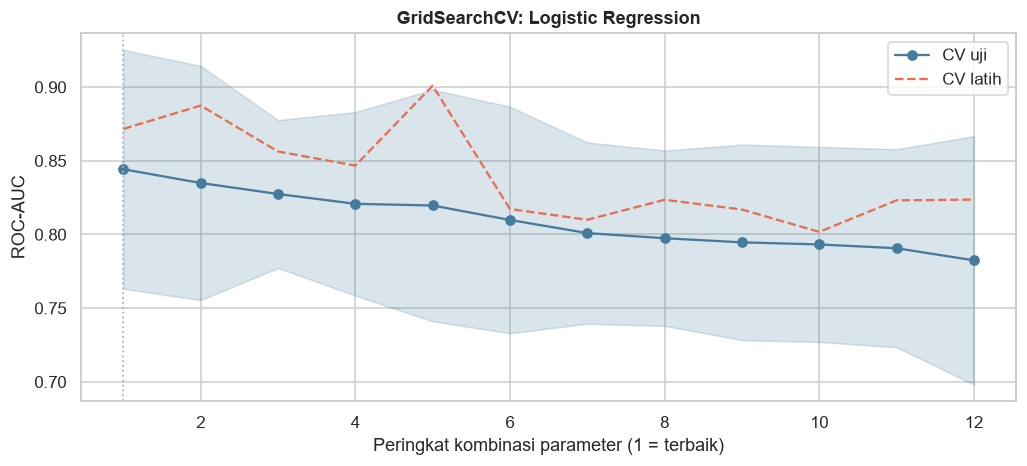

In [7]:
param_grids = {
    "Logistic Regression": {
        "clf__C": [0.01, 0.1, 1.0, 10.0],
    },
    "SVM-RBF": {
        "clf__C": [0.1, 1.0, 10.0],
        "clf__gamma": ["scale", 0.1, 0.01],
    },
    "Random Forest": {
        "clf__n_estimators": [300, 600],
        "clf__max_depth": [None, 6, 12],
        "clf__min_samples_leaf": [1, 2],
    },
    "Gradient Boosting": {
        "clf__n_estimators": [100, 200],
        "clf__learning_rate": [0.05, 0.1],
        "clf__max_depth": [2, 3],
    },
}

k_candidates = [4, 8, 12]
active_param_grid = {"select__k": k_candidates, **param_grids[best_reference_name]}
n_combinations = 1
for values in active_param_grid.values():
    n_combinations *= len(values)

search = GridSearchCV(
    estimator=make_pipeline(reference_models[best_reference_name]),
    param_grid=active_param_grid,
    scoring=SCORING,
    cv=GroupKFold(n_splits=N_SPLITS),
    n_jobs=1,
    refit=True,
    return_train_score=True,
    error_score="raise",
)
search.fit(X_train, y_train, groups=groups_train)

grid_results = pd.DataFrame(search.cv_results_)
grid_results = grid_results[
    [
        "rank_test_score",
        "params",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "std_train_score",
        "mean_fit_time",
    ]
].sort_values("rank_test_score")
grid_results.to_csv(ARTIFACT_DIR / "grid_search_results.csv", index=False)

best_pipeline = search.best_estimator_
assert set(best_pipeline.named_steps) == {"scaler", "select", "clf"}

print(f"Model yang ditala: {best_reference_name}")
print(f"Jumlah kombinasi: {n_combinations} kombinasi x {N_SPLITS} fold")
print(f"ROC-AUC terbaik (CV): {search.best_score_:.4f}")
print(f"Parameter terbaik: {search.best_params_}")

display(grid_results.head(10).round(4))

fig, ax = plt.subplots(figsize=(9.5, 4.4))
ordered = grid_results.sort_values("mean_test_score", ascending=False).reset_index(drop=True)
ax.plot(ordered.index + 1, ordered["mean_test_score"], "o-", color="#457b9d", label="CV uji")
ax.fill_between(
    ordered.index + 1,
    ordered["mean_test_score"] - ordered["std_test_score"],
    ordered["mean_test_score"] + ordered["std_test_score"],
    alpha=0.2,
    color="#457b9d",
)
ax.plot(ordered.index + 1, ordered["mean_train_score"], "--", color="#e76f51", label="CV latih")
ax.axvline(1, color="#adb5bd", linewidth=1.2, linestyle=":")
ax.set_xlabel("Peringkat kombinasi parameter (1 = terbaik)")
ax.set_ylabel("ROC-AUC")
ax.set_title(f"GridSearchCV: {best_reference_name}")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "grid_search_scores.png")
plt.show()


## 6. Simpan artefak model

Pipeline hasil `refit` pada seluruh data latih disimpan sebagai:

1. `artifacts/best_model.joblib` — pipeline utuh: `scaler -> select -> clf`, siap dimuat Tahap 05/06 tanpa langkah tambahan.
2. `artifacts/04_modeling/model_config.json` — nama model, parameter terbaik, skor CV, `random_state`, jumlah fold, daftar NIM train/test, 12 kolom fitur, serta fitur yang terpilih oleh `SelectKBest` setelah refit.
3. `artifacts/04_modeling/feature_list.txt` — daftar fitur dalam format ringkas untuk dibaca manusia.

Konfigurasi juga memuat versi paket yang dipakai pelatihan agar hasil dapat direproduksi. Model ini **belum** diuji pada NIM hold-out; itu urusan Tahap 05.


In [8]:
def json_safe(value):
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple, set)):
        return [json_safe(item) for item in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    return value


selector = best_pipeline.named_steps["select"]
selected_mask = selector.get_support()
selected_features_final = [
    feature for feature, keep in zip(FEATURE_COLUMNS, selected_mask) if keep
]

joblib.dump(best_pipeline, MODEL_PATH)

model_config = {
    "stage": "04_modeling",
    "model_name": best_reference_name,
    "model_class": type(best_pipeline.named_steps["clf"]).__name__,
    "pipeline_steps": [name for name, _ in best_pipeline.steps],
    "best_params": json_safe(search.best_params_),
    "best_cv_roc_auc": float(search.best_score_),
    "reference_cv_roc_auc_mean": float(
        reference_comparison.loc[
            reference_comparison["model"] == best_reference_name, "cv_roc_auc_mean"
        ].iloc[0]
    ),
    "baseline_cv_roc_auc": baseline_roc_auc,
    "cv": {
        "splitter": "GroupKFold",
        "n_splits": N_SPLITS,
        "groups": "nim",
        "scoring": SCORING,
    },
    "holdout": {
        "splitter": "GroupShuffleSplit",
        "test_size": TEST_SIZE,
        "random_state": RANDOM_STATE,
        "n_nim_train": len(nims_train),
        "n_nim_test": len(nims_test),
        "nims_train": nims_train,
        "nims_test": nims_test,
        "n_files_train": int(len(model_train)),
        "n_files_test": int(len(model_test)),
        "class_counts_train": {
            str(key): int(value)
            for key, value in model_train["label"].value_counts().sort_index().items()
        },
        "class_counts_test": {
            str(key): int(value)
            for key, value in model_test["label"].value_counts().sort_index().items()
        },
    },
    "random_state": RANDOM_STATE,
    "feature_columns": FEATURE_COLUMNS,
    "n_features_total": len(FEATURE_COLUMNS),
    "n_features_selected": int(selected_mask.sum()),
    "selected_features_final": selected_features_final,
    "train_rows": int(len(model_train)),
    "library_versions": library_versions.set_index("komponen")["versi"].to_dict(),
    "preprocessing_note": (
        "fitur diambil dari artifacts/features.csv; prapemrosesan audio mengikuti "
        "artifacts/03_data_preparation/preprocessing_contract.json"
    ),
    "created_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
}
model_config = json_safe(model_config)
MODEL_CONFIG_PATH.write_text(
    json.dumps(model_config, ensure_ascii=False, indent=2), encoding="utf-8"
)

feature_list_lines = [
    "# Daftar fitur untuk artifacts/best_model.joblib (Tahap 04)",
    f"# k_fitur_terpilih: {model_config['n_features_selected']} dari "
    f"{model_config['n_features_total']} (SelectKBest f_classif, dipelajari pada training fold)",
    f"# model: {model_config['model_name']} ({model_config['model_class']})",
    "# peringatan: angka fitur pada Tahap 03 bersifat eksploratif; pipeline inilah yang berlaku",
    *model_config["feature_columns"],
]
FEATURE_LIST_PATH.write_text("\n".join(feature_list_lines) + "\n", encoding="utf-8")

display(
    pd.DataFrame(
        {
            "item": [
                "model_name",
                "model_class",
                "best_cv_roc_auc",
                "baseline_cv_roc_auc",
                "best_params",
                "n_features_selected",
                "selected_features_final",
                "n_files_train / n_files_test",
                "n_nim_train / n_nim_test",
                "random_state",
            ],
            "nilai": [
                model_config["model_name"],
                model_config["model_class"],
                f"{model_config['best_cv_roc_auc']:.4f}",
                f"{model_config['baseline_cv_roc_auc']:.4f}",
                str(model_config["best_params"]),
                model_config["n_features_selected"],
                ", ".join(model_config["selected_features_final"]),
                f"{model_config['holdout']['n_files_train']} / "
                f"{model_config['holdout']['n_files_test']}",
                f"{model_config['holdout']['n_nim_train']} / "
                f"{model_config['holdout']['n_nim_test']}",
                model_config["random_state"],
            ],
        }
    )
)
print(f"Model disimpan: {MODEL_PATH}")
print(f"Konfigurasi: {MODEL_CONFIG_PATH}")
print(f"Daftar fitur: {FEATURE_LIST_PATH}")


,item,nilai
0,model_name,Logistic Regression
1,model_class,LogisticRegression
2,best_cv_roc_auc,0.8442
3,baseline_cv_roc_auc,0.5000
4,best_params,"{'clf__C': 10.0, 'select__k': 8}"
5,n_features_selected,8
6,selected_features_final,"mse_energy, rms_mean, rms_std, rms_max, rms_mi..."
7,n_files_train / n_files_test,136 / 40
8,n_nim_train / n_nim_test,27 / 7
9,random_state,42


Model disimpan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\best_model.joblib
Konfigurasi: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\04_modeling\model_config.json
Daftar fitur: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\04_modeling\feature_list.txt


## 7. Validasi akhir dan serah-terima Tahap 05

Validasi memastikan hasil Tahap 04 dapat dipakai Tahap 05 tanpa perbaikan diam-diam.

### Checklist

1. Gerbang Tahap 03 (PASS, 176 baris fitur, 12 fitur bersih) tetap terpenuhi.
2. Hold-out terkunci: 20% NIM, train dan test tidak beririsan, seluruh NIM tercakup, dan komposisi per file/kelas dilaporkan.
3. `GroupKFold` tidak pernah mencampur satu NIM ke dua sisi fold; seluruh baris CV berasal dari NIM train.
4. NIM hold-out tidak pernah masuk `GridSearchCV` maupun data refit.
5. Empat model kandidat dibandingkan dan baseline 0,50 tercatat.
6. Pipeline tersimpan memiliki tepat tiga langkah `scaler`, `select`, `clf`; tidak ada PCA.
7. `best_model.joblib` dapat dimuat ulang, mengeluarkan label {0,1} dan probabilitas berada di [0,1] dengan jumlah baris 1.
8. `model_config.json` dan `feature_list.txt` memuat parameter, fold, scoring, `random_state`, dan daftar fitur.
9. Tahap 05 hanya boleh memakai NIM test yang sudah dikunci; model **belum** diuji pada tahap ini.


In [9]:
loaded_model = joblib.load(MODEL_PATH)
probe_X = X_train[:8]
probe_pred = loaded_model.predict(probe_X)
probe_pred_again = loaded_model.predict(probe_X)
probe_proba = loaded_model.predict_proba(probe_X)

saved_config = json.loads(MODEL_CONFIG_PATH.read_text(encoding="utf-8"))
feature_list = [
    line.strip()
    for line in FEATURE_LIST_PATH.read_text(encoding="utf-8").splitlines()
    if line.strip() and not line.startswith("#")
]

cv_disjoint = True
cv_within_train = True
fold_audit_rows = []
train_nims_set = set(nims_train)
for fold_index, (fit_idx, val_idx) in enumerate(
    GroupKFold(n_splits=N_SPLITS).split(X_train, y_train, groups=groups_train)
):
    fit_nims = set(model_train["nim"].iloc[fit_idx])
    val_nims = set(model_train["nim"].iloc[val_idx])
    if fit_nims & val_nims:
        cv_disjoint = False
    if not val_nims.issubset(train_nims_set):
        cv_within_train = False
    fold_audit_rows.append(
        {
            "fold": fold_index,
            "n_nim_fit": len(fit_nims),
            "n_nim_validate": len(val_nims),
            "overlap_nim": len(fit_nims & val_nims),
            "n_file_validate": int(len(val_idx)),
            "n_class_0_validate": int((y_train[val_idx] == 0).sum()),
            "n_class_1_validate": int((y_train[val_idx] == 1).sum()),
        }
    )
cv_fold_audit = pd.DataFrame(fold_audit_rows)
cv_fold_audit.to_csv(ARTIFACT_DIR / "cv_fold_audit.csv", index=False)

pipeline_steps = list(loaded_model.named_steps)
required_config_keys = {
    "stage",
    "model_name",
    "best_params",
    "best_cv_roc_auc",
    "baseline_cv_roc_auc",
    "cv",
    "holdout",
    "random_state",
    "feature_columns",
    "n_features_selected",
    "selected_features_final",
}
figures_expected = [
    "holdout_composition.png",
    "cv_model_comparison.png",
    "grid_search_scores.png",
]
class_counts = features["label"].value_counts().to_dict()

checks = {
    "gate03_pass": (
        stage3_validation["status"] == "PASS"
        and stage3_validation["checks_passed"] == stage3_validation["checks_total"]
    ),
    "features_176": len(features) == 176,
    "fitur_12_bersih": (
        set(FEATURE_COLUMNS).issubset(features.columns)
        and not features[FEATURE_COLUMNS].isna().any().any()
        and np.isfinite(features[FEATURE_COLUMNS].to_numpy(dtype=float)).all()
    ),
    "kelas_88_88": int(class_counts.get(0, 0)) == 88 and int(class_counts.get(1, 0)) == 88,
    "holdout_nim_test_sebesar_20persen": len(nims_test)
    == int(np.ceil(TEST_SIZE * len(nims_all))),
    "holdout_disjoint": set(nims_train).isdisjoint(set(nims_test)),
    "holdout_menutup_34_nim": set(nims_train) | set(nims_test) == set(nims_all),
    "holdout_file_176": (
        len(holdout_file_split) == 176
        and int(holdout_file_split["split"].isin(["train", "test"]).sum()) == 176
    ),
    "holdout_kelas_terlapor": (
        int(holdout_file_split.loc[holdout_file_split["split"] == "train"].shape[0]) > 0
        and int(holdout_file_split.loc[holdout_file_split["split"] == "test"].shape[0]) > 0
    ),
    "cv_groups_disjoint": cv_disjoint,
    "cv_hanya_nim_train": cv_within_train,
    "data_latih_tanpa_holdout": (
        set(model_train["nim"]).isdisjoint(set(nims_test))
        and len(model_train) + len(model_test) == 176
    ),
    "empat_model_dibandingkan": len(reference_comparison) == 4,
    "baseline_roc_auc_050": abs(baseline_roc_auc - 0.5) < 1e-9,
    "grid_search_selesai": bool(
        np.isfinite(search.best_score_) and len(grid_results) > 0
    ),
    "pipeline_tiga_langkah": pipeline_steps == ["scaler", "select", "clf"],
    "seleksi_fitur_dalam_pipeline": isinstance(
        loaded_model.named_steps["select"], SelectKBest
    ),
    "tanpa_pca": "pca" not in pipeline_steps,
    "joblib_dimuat": MODEL_PATH.is_file() and isinstance(loaded_model, Pipeline),
    "prediksi_valid": (
        len(probe_pred) == len(probe_X)
        and set(np.unique(probe_pred)).issubset({0, 1})
        and probe_proba.shape == (len(probe_X), 2)
        and float(probe_proba.min()) >= 0.0
        and float(probe_proba.max()) <= 1.0
        and bool(np.allclose(probe_proba.sum(axis=1), 1.0))
    ),
    "prediksi_deterministik": bool(np.array_equal(probe_pred, probe_pred_again)),
    "konfigurasi_lengkap": required_config_keys.issubset(saved_config.keys()),
    "konfigurasi_konsisten": (
        saved_config["model_name"] == best_reference_name
        and abs(saved_config["best_cv_roc_auc"] - float(search.best_score_)) < 1e-12
        and saved_config["holdout"]["nims_train"] == nims_train
        and saved_config["holdout"]["nims_test"] == nims_test
    ),
    "daftar_fitur_12": set(feature_list) == set(FEATURE_COLUMNS),
    "fitur_terpilih_valid": (
        0
        < int(saved_config["n_features_selected"])
        <= len(FEATURE_COLUMNS)
        and set(saved_config["selected_features_final"]).issubset(set(FEATURE_COLUMNS))
        and len(saved_config["selected_features_final"])
        == int(saved_config["n_features_selected"])
    ),
    "random_state_tercatat": saved_config["random_state"] == RANDOM_STATE,
    "cv_tercatat": (
        saved_config["cv"]["n_splits"] == N_SPLITS
        and saved_config["cv"]["scoring"] == SCORING
        and saved_config["cv"]["groups"] == "nim"
    ),
    "holdout_nims_tercatat": (
        saved_config["holdout"]["nims_train"] == nims_train
        and saved_config["holdout"]["nims_test"] == nims_test
    ),
    "figures_tersimpan": all(
        (FIGURE_DIR / name).is_file() for name in figures_expected
    ),
}

check_table = pd.DataFrame(
    {"pemeriksaan": list(checks.keys()), "lulus": list(checks.values())}
)
check_table["status"] = np.where(check_table["lulus"], "PASS", "FAIL")

if not all(checks.values()):
    display(check_table)
    raise ValueError("Validasi akhir Tahap 04 gagal.")

check_table.to_csv(ARTIFACT_DIR / "validation_checks.csv", index=False)

validation_summary = {
    "status": "PASS",
    "model_name": best_reference_name,
    "model_class": saved_config["model_class"],
    "best_cv_roc_auc": float(search.best_score_),
    "baseline_cv_roc_auc": baseline_roc_auc,
    "n_combinations": int(len(grid_results)),
    "best_params": saved_config["best_params"],
    "n_features_total": len(FEATURE_COLUMNS),
    "n_features_selected": int(saved_config["n_features_selected"]),
    "selected_features_final": saved_config["selected_features_final"],
    "n_nim_total": len(nims_all),
    "n_nim_train": len(nims_train),
    "n_nim_test": len(nims_test),
    "n_files_train": int(len(model_train)),
    "n_files_test": int(len(model_test)),
    "class_counts_train": saved_config["holdout"]["class_counts_train"],
    "class_counts_test": saved_config["holdout"]["class_counts_test"],
    "n_splits": N_SPLITS,
    "scoring": SCORING,
    "random_state": RANDOM_STATE,
    "checks_passed": int(check_table["lulus"].sum()),
    "checks_total": int(len(check_table)),
    "holdout_tested_in_stage_04": False,
}
(ARTIFACT_DIR / "validation_summary.json").write_text(
    json.dumps(validation_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

validation_report_lines = [
    "# Laporan Validasi Tahap 04",
    "",
    "Status: **PASS**",
    "",
    "## Angka aktual",
    "",
    f"- Model terpilih: {best_reference_name} ({saved_config['model_class']})",
    f"- ROC-AUC CV terbaik: {search.best_score_:.4f} (baseline {baseline_roc_auc:.2f})",
    f"- Kombinasi hyperparameter: {len(grid_results)}",
    f"- Fitur terpilih setelah refit: {saved_config['n_features_selected']} dari {len(FEATURE_COLUMNS)}",
    f"- NIM train/test: {len(nims_train)} / {len(nims_test)}",
    f"- File train/test: {len(model_train)} / {len(model_test)}",
    f"- Fold GroupKFold: {N_SPLITS} (grup = NIM, overlap 0)",
    f"- Pemeriksaan lulus: {check_table['lulus'].sum()}/{len(check_table)}",
    "",
    "## Catatan",
    "",
    "- Hold-out NIM **belum** dipakai untuk evaluasi pada tahap ini.",
    "- Uji hold-out, kurva ROC/PR, confusion matrix, dan classification report dikerjakan di Tahap 05.",
    "- Scaler dan seleksi fitur berada di dalam pipeline sehingga tidak ada kebocoran preprocessing.",
    "- Tidak ada PCA.",
]
(ARTIFACT_DIR / "validation_report.md").write_text(
    "\n".join(validation_report_lines) + "\n", encoding="utf-8"
)

display(check_table)
print("Validasi akhir Tahap 04: PASS")
print(f"Laporan: {ARTIFACT_DIR / 'validation_report.md'}")


,pemeriksaan,lulus,status
0,gate03_pass,True,PASS
1,features_176,True,PASS
2,fitur_12_bersih,True,PASS
3,kelas_88_88,True,PASS
4,holdout_nim_test_sebesar_20persen,True,PASS
5,holdout_disjoint,True,PASS
6,holdout_menutup_34_nim,True,PASS
7,holdout_file_176,True,PASS
8,holdout_kelas_terlapor,True,PASS
9,cv_groups_disjoint,True,PASS


Validasi akhir Tahap 04: PASS
Laporan: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\04_modeling\validation_report.md


In [10]:
def md_table(frame, max_rows=None):
    view = frame if max_rows is None else frame.head(max_rows)
    columns = [str(column) for column in view.columns]
    lines = [
        "| " + " | ".join(columns) + " |",
        "|" + "|".join(["---"] * len(columns)) + "|",
    ]
    for row in view.itertuples(index=False):
        values = []
        for value in row:
            if isinstance(value, (float, np.floating)):
                text = f"{value:.6g}"
            elif isinstance(value, (bool, np.bool_)):
                text = str(bool(value))
            else:
                text = str(value)
            values.append(text.replace("|", "\\|").replace("\n", " "))
        lines.append("| " + " | ".join(values) + " |")
    if len(frame) > len(view):
        lines.append("")
        lines.append(f"*Menampilkan {len(view)} dari {len(frame)} baris.*")
    return "\n".join(lines)


best_params_text = (
    ", ".join(f"`{key}` = `{value}`" for key, value in saved_config["best_params"].items())
)
split_view = split_summary.reset_index()
comparison_view = comparison.round(4)
grid_top = grid_results.head(5).copy()
grid_top["params"] = grid_top["params"].astype(str)
fold_view = cv_fold_audit

report = f"""# 04 — Modeling: Laporan Aktual

## Ringkasan

Tahap 04 membandingkan empat model pada data latih berbasis NIM, lalu menala kandidat terbaik dengan `GridSearchCV`. Hold-out 20% NIM dikunci lebih dulu dan **belum** disentuh evaluasi.

- Model terpilih: **{best_reference_name}** (`{saved_config['model_class']}`).
- ROC-AUC CV terbaik: **{search.best_score_:.4f}** (std {grid_results.sort_values('rank_test_score').iloc[0]['std_test_score']:.4f}); baseline prior: **{baseline_roc_auc:.4f}**.
- Konfigurasi CV: `GroupKFold(n_splits={N_SPLITS})`, grup = NIM, scoring `{SCORING}`, `random_state={RANDOM_STATE}`.
- Hold-out: {len(nims_test)} NIM test ({len(model_test)} file) dan {len(nims_train)} NIM train ({len(model_train)} file) dari total {len(nims_all)} NIM / {len(features)} file.
- Fitur terpilih setelah refit: {saved_config['n_features_selected']} dari {len(FEATURE_COLUMNS)} fitur, dipelajari di dalam pipeline.
- Pemeriksaan validasi: {check_table['lulus'].sum()}/{len(check_table)} PASS.

## Penguncian hold-out

{md_table(split_view)}

NIM test: {", ".join(f"`{nim}`" for nim in nims_test)}.

NIM ini tidak pernah masuk perbandingan model maupun `GridSearchCV`; uji terhadap NIM tersebut baru dilakukan di Tahap 05.

## Baseline dan perbandingan empat model

Baseline `DummyClassifier(strategy="prior")` memberi ROC-AUC {baseline_roc_auc:.4f} karena dua kelas hampir seimbang. Angka model harus dibaca relatif terhadap baseline ini.

{md_table(comparison_view)}

Selisih ROC-AUC antar fold tersimpan di `cv_fold_audit.csv` dan `cv_fold_scores.csv`. Semua model berada di atas baseline, tetapi peringkat CV ini belum membuktikan generalisasi ke NIM yang belum pernah dilihat.

## GridSearchCV kandidat terbaik

- Model yang ditala: **{best_reference_name}**; kombinasi: **{len(grid_results)}** dengan {N_SPLITS} fold.
- Parameter terbaik: {best_params_text}.
- Skor CV terbaik: **{search.best_score_:.4f}**; skor latih: {grid_results.sort_values('rank_test_score').iloc[0]['mean_train_score']:.4f}.
- Kandidat fitur: `select__k` ikut dicari sehingga jumlah fitur ditentukan di dalam fold latih.

Kandidat terbaik (5 kombinasi teratas):

{md_table(grid_top[['rank_test_score', 'params', 'mean_test_score', 'std_test_score', 'mean_train_score']])}

Audit per fold:

{md_table(fold_view)}

## Artefak model

- `artifacts/best_model.joblib`: pipeline `scaler -> select -> clf` hasil refit pada seluruh NIM train.
- `artifacts/04_modeling/model_config.json`: model, parameter, skor, versi paket, dan daftar NIM train/test.
- `artifacts/04_modeling/feature_list.txt`: daftar 12 fitur beserta catatan jumlah fitur terpilih.
- `artifacts/04_modeling/holdout_split.csv` dan `holdout_file_split.csv`: pembagian terkunci.
- `artifacts/04_modeling/model_comparison.csv`, `grid_search_results.csv`, `cv_fold_scores.csv`, `cv_fold_audit.csv`.
- `artifacts/04_modeling/validation_report.md` dan `validation_summary.json`.
- Gambar: `holdout_composition.png`, `cv_model_comparison.png`, `grid_search_scores.png`.

## Validasi akhir

Semua pemeriksaan lulus: **{check_table['lulus'].sum()}/{len(check_table)}**.

{md_table(check_table[['pemeriksaan', 'status']])}

## Batasan

- Hold-out **belum** dievaluasi; skor {search.best_score_:.4f} adalah CV pada {len(nims_train)} NIM train, bukan angka kelayakan.
- Kelayakan ROC-AUC ≥ 0,85 hanya dinilai pada Tahap 05 terhadap {len(nims_test)} NIM test.
- Kandidat terbaik memperoleh keuntungan tuning, sementara tiga model lain memakai parameter bawaan; perbandingan adil akhir ada di hasil hold-out.
- Seleksi fitur (`SelectKBest` berbasis ANOVA) bergantung pada fold; daftar fitur terpilih pada pipeline dapat berbeda dari kandidat eksploratif Tahap 03.
- Probabilitas keluaran (terutama `SVC(probability=True)`) adalah skor model, bukan probabilitas terkalibrasi.
- Tidak ada PCA, tidak ada data karantina yang dipakai, dan `raw_audio/` tidak diubah.

## Kesimpulan dan keputusan untuk Tahap 05

1. Muat `artifacts/best_model.joblib` dan `artifacts/04_modeling/model_config.json`; jangan melatih ulang model.
2. Pakai **hanya** NIM test: {", ".join(f"`{nim}`" for nim in nims_test)}; NIM train tidak boleh muncul di metrik hold-out.
3. Ekstraksi fitur pada file uji harus identik dengan Tahap 03 (kontrak `preprocessing_contract.json`).
4. Laporkan ROC-AUC, PR-AUC, precision, recall, F1, accuracy, confusion matrix, dan classification report, lengkap dengan jumlah NIM test.
5. Bandingkan hasil dengan baseline 0,50 dan syarat kelayakan ROC-AUC ≥ 0,85; bila di bawah syarat, laporkan apa adanya.

**Modeling selesai dan tervalidasi. Hold-out belum diuji.**
"""

(ARTIFACT_DIR / "modeling_report.md").write_text(report, encoding="utf-8")

modeling_summary = {
    "status": "PASS",
    "model_name": best_reference_name,
    "model_class": saved_config["model_class"],
    "best_cv_roc_auc": float(search.best_score_),
    "baseline_cv_roc_auc": baseline_roc_auc,
    "n_combinations": int(len(grid_results)),
    "best_params": saved_config["best_params"],
    "n_features_selected": int(saved_config["n_features_selected"]),
    "selected_features_final": saved_config["selected_features_final"],
    "n_nim_train": len(nims_train),
    "n_nim_test": len(nims_test),
    "n_files_train": int(len(model_train)),
    "n_files_test": int(len(model_test)),
    "n_splits": N_SPLITS,
    "scoring": SCORING,
    "random_state": RANDOM_STATE,
    "nims_test": nims_test,
    "holdout_tested_in_stage_04": False,
}
(ARTIFACT_DIR / "modeling_summary.json").write_text(
    json.dumps(modeling_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

print(f"Laporan tahap: {ARTIFACT_DIR / 'modeling_report.md'}")
display(Markdown(report))


Laporan tahap: C:\Users\ASUS\Downloads\dataset_30_detik\artifacts\04_modeling\modeling_report.md


# 04 — Modeling: Laporan Aktual

## Ringkasan

Tahap 04 membandingkan empat model pada data latih berbasis NIM, lalu menala kandidat terbaik dengan `GridSearchCV`. Hold-out 20% NIM dikunci lebih dulu dan **belum** disentuh evaluasi.

- Model terpilih: **Logistic Regression** (`LogisticRegression`).
- ROC-AUC CV terbaik: **0.8442** (std 0.0810); baseline prior: **0.5000**.
- Konfigurasi CV: `GroupKFold(n_splits=5)`, grup = NIM, scoring `roc_auc`, `random_state=42`.
- Hold-out: 7 NIM test (40 file) dan 27 NIM train (136 file) dari total 34 NIM / 176 file.
- Fitur terpilih setelah refit: 8 dari 12 fitur, dipelajari di dalam pipeline.
- Pemeriksaan validasi: 29/29 PASS.

## Penguncian hold-out

| split | n_files | n_nim | n_class_0 | n_class_1 |
|---|---|---|---|---|
| train | 136 | 27 | 67 | 69 |
| test | 40 | 7 | 21 | 19 |

NIM test: `24-068`, `24-100`, `24-119`, `24-131`, `24-145`, `24-168`, `24-169`.

NIM ini tidak pernah masuk perbandingan model maupun `GridSearchCV`; uji terhadap NIM tersebut baru dilakukan di Tahap 05.

## Baseline dan perbandingan empat model

Baseline `DummyClassifier(strategy="prior")` memberi ROC-AUC 0.5000 karena dua kelas hampir seimbang. Angka model harus dibaca relatif terhadap baseline ini.

| model | cv_roc_auc_mean | cv_roc_auc_std | train_roc_auc_mean | cv_accuracy_mean | cv_precision_mean | cv_recall_mean | cv_f1_mean |
|---|---|---|---|---|---|---|---|
| Logistic Regression | 0.8349 | 0.0795 | 0.8875 | 0.7204 | 0.7633 | 0.7026 | 0.7096 |
| Random Forest | 0.7811 | 0.0712 | 1 | 0.6989 | 0.6995 | 0.7641 | 0.7167 |
| SVM-RBF | 0.7738 | 0.0842 | 0.911 | 0.7127 | 0.7667 | 0.6892 | 0.6978 |
| Gradient Boosting | 0.7569 | 0.0899 | 1 | 0.6859 | 0.6931 | 0.7508 | 0.7084 |
| Baseline (prior) | 0.5 | 0 | 0.5 | 0.4777 | 0.3931 | 0.8 | 0.5268 |

Selisih ROC-AUC antar fold tersimpan di `cv_fold_audit.csv` dan `cv_fold_scores.csv`. Semua model berada di atas baseline, tetapi peringkat CV ini belum membuktikan generalisasi ke NIM yang belum pernah dilihat.

## GridSearchCV kandidat terbaik

- Model yang ditala: **Logistic Regression**; kombinasi: **12** dengan 5 fold.
- Parameter terbaik: `clf__C` = `10.0`, `select__k` = `8`.
- Skor CV terbaik: **0.8442**; skor latih: 0.8716.
- Kandidat fitur: `select__k` ikut dicari sehingga jumlah fitur ditentukan di dalam fold latih.

Kandidat terbaik (5 kombinasi teratas):

| rank_test_score | params | mean_test_score | std_test_score | mean_train_score |
|---|---|---|---|---|
| 1 | {'clf__C': 10.0, 'select__k': 8} | 0.844245 | 0.0810337 | 0.871605 |
| 2 | {'clf__C': 1.0, 'select__k': 12} | 0.834938 | 0.0794608 | 0.887479 |
| 3 | {'clf__C': 0.1, 'select__k': 12} | 0.827464 | 0.050196 | 0.856319 |
| 4 | {'clf__C': 1.0, 'select__k': 8} | 0.820797 | 0.0622585 | 0.846709 |
| 5 | {'clf__C': 10.0, 'select__k': 12} | 0.819663 | 0.0786385 | 0.900944 |

Audit per fold:

| fold | n_nim_fit | n_nim_validate | overlap_nim | n_file_validate | n_class_0_validate | n_class_1_validate |
|---|---|---|---|---|---|---|
| 0 | 21 | 6 | 0 | 29 | 14 | 15 |
| 1 | 21 | 6 | 0 | 29 | 16 | 13 |
| 2 | 22 | 5 | 0 | 26 | 13 | 13 |
| 3 | 22 | 5 | 0 | 26 | 11 | 15 |
| 4 | 22 | 5 | 0 | 26 | 13 | 13 |

## Artefak model

- `artifacts/best_model.joblib`: pipeline `scaler -> select -> clf` hasil refit pada seluruh NIM train.
- `artifacts/04_modeling/model_config.json`: model, parameter, skor, versi paket, dan daftar NIM train/test.
- `artifacts/04_modeling/feature_list.txt`: daftar 12 fitur beserta catatan jumlah fitur terpilih.
- `artifacts/04_modeling/holdout_split.csv` dan `holdout_file_split.csv`: pembagian terkunci.
- `artifacts/04_modeling/model_comparison.csv`, `grid_search_results.csv`, `cv_fold_scores.csv`, `cv_fold_audit.csv`.
- `artifacts/04_modeling/validation_report.md` dan `validation_summary.json`.
- Gambar: `holdout_composition.png`, `cv_model_comparison.png`, `grid_search_scores.png`.

## Validasi akhir

Semua pemeriksaan lulus: **29/29**.

| pemeriksaan | status |
|---|---|
| gate03_pass | PASS |
| features_176 | PASS |
| fitur_12_bersih | PASS |
| kelas_88_88 | PASS |
| holdout_nim_test_sebesar_20persen | PASS |
| holdout_disjoint | PASS |
| holdout_menutup_34_nim | PASS |
| holdout_file_176 | PASS |
| holdout_kelas_terlapor | PASS |
| cv_groups_disjoint | PASS |
| cv_hanya_nim_train | PASS |
| data_latih_tanpa_holdout | PASS |
| empat_model_dibandingkan | PASS |
| baseline_roc_auc_050 | PASS |
| grid_search_selesai | PASS |
| pipeline_tiga_langkah | PASS |
| seleksi_fitur_dalam_pipeline | PASS |
| tanpa_pca | PASS |
| joblib_dimuat | PASS |
| prediksi_valid | PASS |
| prediksi_deterministik | PASS |
| konfigurasi_lengkap | PASS |
| konfigurasi_konsisten | PASS |
| daftar_fitur_12 | PASS |
| fitur_terpilih_valid | PASS |
| random_state_tercatat | PASS |
| cv_tercatat | PASS |
| holdout_nims_tercatat | PASS |
| figures_tersimpan | PASS |

## Batasan

- Hold-out **belum** dievaluasi; skor 0.8442 adalah CV pada 27 NIM train, bukan angka kelayakan.
- Kelayakan ROC-AUC ≥ 0,85 hanya dinilai pada Tahap 05 terhadap 7 NIM test.
- Kandidat terbaik memperoleh keuntungan tuning, sementara tiga model lain memakai parameter bawaan; perbandingan adil akhir ada di hasil hold-out.
- Seleksi fitur (`SelectKBest` berbasis ANOVA) bergantung pada fold; daftar fitur terpilih pada pipeline dapat berbeda dari kandidat eksploratif Tahap 03.
- Probabilitas keluaran (terutama `SVC(probability=True)`) adalah skor model, bukan probabilitas terkalibrasi.
- Tidak ada PCA, tidak ada data karantina yang dipakai, dan `raw_audio/` tidak diubah.

## Kesimpulan dan keputusan untuk Tahap 05

1. Muat `artifacts/best_model.joblib` dan `artifacts/04_modeling/model_config.json`; jangan melatih ulang model.
2. Pakai **hanya** NIM test: `24-068`, `24-100`, `24-119`, `24-131`, `24-145`, `24-168`, `24-169`; NIM train tidak boleh muncul di metrik hold-out.
3. Ekstraksi fitur pada file uji harus identik dengan Tahap 03 (kontrak `preprocessing_contract.json`).
4. Laporkan ROC-AUC, PR-AUC, precision, recall, F1, accuracy, confusion matrix, dan classification report, lengkap dengan jumlah NIM test.
5. Bandingkan hasil dengan baseline 0,50 dan syarat kelayakan ROC-AUC ≥ 0,85; bila di bawah syarat, laporkan apa adanya.

**Modeling selesai dan tervalidasi. Hold-out belum diuji.**


## Kesimpulan dan keputusan untuk tahap 05

1. **Hold-out terkunci:** `GroupShuffleSplit(test_size=0.2, random_state=42)` pada 34 NIM menghasilkan **27 NIM train (136 file, kelas 67 non-berisik : 69 berisik)** dan **7 NIM test (40 file, kelas 21 : 19)**. NIM test: `24-068`, `24-100`, `24-119`, `24-131`, `24-145`, `24-168`, `24-169`. Pembagian disimpan di `holdout_split.csv` dan `holdout_file_split.csv`, dan **belum pernah** dipakai untuk CV atau `GridSearchCV`.
2. **Baseline jujur:** `DummyClassifier(strategy="prior")` memberi ROC-AUC **0,50** pada GroupKFold 5 fold; seluruh kandidat dibaca relatif terhadap angka ini.
3. **Perbandingan empat model (data latih saja, grup = NIM, overlap fold 0):** Logistic Regression **0,8349**, Random Forest **0,7811**, SVM-RBF **0,7738**, Gradient Boosting **0,7569**.
4. **GridSearchCV kandidat terbaik:** pada Logistic Regression dengan 12 kombinasi (`C ∈ {0.01, 0.1, 1, 10}` × `select__k ∈ {4, 8, 12}`), terbaik **`C = 10`, `k = 8`** dengan ROC-AUC CV **0,8442** (std 0,0810).
5. **Model tersimpan:** `artifacts/best_model.joblib` = pipeline `StandardScaler -> SelectKBest -> LogisticRegression` hasil refit pada 136 file train, memakai **8 dari 12 fitur** yang dipilih di dalam pipeline: `mse_energy`, `rms_mean`, `rms_std`, `rms_max`, `rms_min`, `zcr_mean`, `spectral_centroid_mean`, `spectral_rolloff_mean`. Konfigurasi di `model_config.json`, daftar fitur di `feature_list.txt`.
6. **Validasi:** **29/29 pemeriksaan PASS** — gerbang Tahap 03, sisi split beririsan nol, fold CV tanpa NIM ganda, data latih bebas NIM hold-out, pipeline tiga langkah tanpa PCA, joblib dapat dimuat dan prediksi deterministik.
7. **Belum dilakukan:** uji terhadap 7 NIM test, kurva ROC/PR, confusion matrix, classification report, dan penilaian syarat ROC-AUC ≥ 0,85 — semuanya urusan Tahap 05.
8. **Rencana 05:** muat `best_model.joblib` tanpa melatih ulang, ekstraksi fitur identik dengan kontrak Tahap 03, evaluasi **hanya** pada NIM test, bandingkan dengan baseline 0,50 dan syarat kelayakan 0,85, lalu laporkan metrik aktual beserta limitasinya apa adanya.

**Modeling selesai dan tervalidasi. Hold-out belum diuji.**
